# Step 1 — 피처 엔지니어링 (Feature Engineering)

- **목적 (Objective)**: §1-3 EDA에서 확인된 데이터 고유 구조를 명시적 피처로 인코딩하여 기준선 OOF AUC `0.95866` 초과.
- **설계 원칙 (Design Principle)**: 일반적인 피처 나열이 아니라, **EDA가 실제로 관측한 현상에만 근거**해 4개 그룹을 설계한다.
- **실험 방식**: 그룹을 **누적 추가**하며 매 단계 5-Fold OOF를 측정. 개선 없는 그룹은 폐기하고 기록만 남긴다 (§3-4 단일 변경 원칙).

| 그룹 | 피처 | EDA 근거 |
|---|---|---|
| **F1** | 13개 평점의 `<col>_is_zero` 플래그 | 0점 역전 현상 (`Online boarding` 0점→만족률 62%, `Inflight wifi` 0점→88%) |
| **F2** | 평점 집계 `rating_mean/std/sum/zero_count` | 서비스 전반 만족 수준의 행 단위 요약 |
| **F3** | `net_delay`, `has_delay` | 지연 Zero-inflated 구조 (출발 지연 0분이 90.8%) |
| **F4** | `Age_freq`, `Flight Distance_freq` | MLP 노트북에서 사용 중인 빈도 인코딩 |

### 채택 기준 (Acceptance Rule) — §3-4
1. Pooled OOF AUC > 직전 최고치
2. **5개 Fold 중 4개 이상에서 개선** (Fold별 AUC std ≈ 0.00058 로 목표 개선폭과 자릿수가 같으므로 필수)

Fold 계약(§3-1)이 분할을 고정하므로 모든 비교는 **동일 Fold 기준 대응표본(paired)** 이다.

---

## 1. 환경 설정 (Environment Setup)

In [1]:
import time
from pathlib import Path

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold

SEED = 42
START_TIME = time.time()

COLOR_MAIN = "#2a78d6"
COLOR_ALT = "#eb6834"
plt.rcParams.update({
    "figure.dpi": 100,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e4e3df",
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "axes.titleweight": "bold",
})
print("lightgbm", lgb.__version__, "| pandas", pd.__version__)

lightgbm 4.7.0 | pandas 3.0.5


In [2]:
REQUIRED_FILES = ["train.csv", "test.csv", "sample_submission.csv"]


def has_all_files(folder: Path) -> bool:
    return all((folder / name).is_file() for name in REQUIRED_FILES)


def find_data_dir() -> Path:
    kaggle_root = Path("/kaggle/input")
    if kaggle_root.exists():
        candidates = sorted({p.parent for p in kaggle_root.glob("**/train.csv") if has_all_files(p.parent)})
    else:
        candidates = list(dict.fromkeys(p.resolve() for p in (Path("data"), Path("../data")) if has_all_files(p)))
    if len(candidates) == 1:
        return candidates[0]
    raise FileNotFoundError(f"데이터 폴더 탐색 실패: {candidates}")


DATA_DIR = find_data_dir()
OUT_DIR = Path("/kaggle/working/outputs") if Path("/kaggle/working").exists() else Path("outputs")
OUT_DIR.mkdir(parents=True, exist_ok=True)
PRED_DIR = OUT_DIR / "predictions"      # 모델별 OOF / Test 예측 (§3-2 산출물 계약)
REPORT_DIR = OUT_DIR / "reports"        # 실험 요약 · 탐색 로그
for _d in (PRED_DIR, REPORT_DIR):
    _d.mkdir(parents=True, exist_ok=True)

train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")

TARGET = "satisfaction"
CAT_COLS = ["Gender", "Customer Type", "Type of Travel", "Class"]
NUM_COLS = [c for c in train.columns if c not in CAT_COLS + ["id", TARGET]]
RATING_COLS = [c for c in NUM_COLS if train[c].max() <= 5]

y = train[TARGET].astype(int)
print(f"평점 피처 {len(RATING_COLS)}개:", RATING_COLS)

평점 피처 13개: ['Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking', 'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment', 'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service', 'Cleanliness']


## 2. Fold 계약 및 평가 함수 (Fold Contract & Evaluation Harness)

- **Fold 계약 (§3-1)**: Step 0 및 MLP 노트북과 **동일한** `StratifiedKFold(5, shuffle=True, random_state=42)`.
- **하이퍼파라미터 고정**: `LGB_PARAMS` 는 기준선과 동일하게 유지한다. 본 단계의 단일 변경점은 **피처뿐**이다.
- **누수 방지**: F1~F3은 행 단위 변환이므로 전체 적용이 안전하다.
  **F4(빈도 인코딩)만 통계량을 추정**하므로 반드시 **Fold별 학습 세트에서만 fit** 한다 (`evaluate(..., use_freq=True)` 분기).

In [3]:
N_FOLDS = 5
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
FOLDS = list(skf.split(train, y))

fold_id = np.full(len(train), -1)
for k, (_, va_idx) in enumerate(FOLDS):
    fold_id[va_idx] = k
assert (fold_id >= 0).all()

# Step 0 산출물과 fold 체계가 동일한지 즉시 검증 (스태킹 정합성의 전제)
_ref = pd.read_csv(PRED_DIR / "oof_lgbm.csv", usecols=["id", "fold"])
_chk = pd.DataFrame({"id": train["id"].values, "fold": fold_id}).merge(
    _ref, on="id", suffixes=("_new", "_ref"), validate="one_to_one")
assert len(_chk) == len(train) and (_chk["fold_new"] == _chk["fold_ref"]).all(), "Fold 계약 불일치"
print("fold 계약 검증 PASS")

LGB_PARAMS = {
    "objective": "binary", "metric": "auc",
    "learning_rate": 0.05, "num_leaves": 63,
    "seed": SEED, "verbose": -1,
}

FREQ_COLS = ["Age", "Flight Distance"]


def add_freq_features(fit_df, *apply_dfs):
    """빈도 인코딩: 반드시 fit_df(= fold 학습 세트)에서만 카운트를 추정한다."""
    counts = {c: fit_df[c].value_counts() for c in FREQ_COLS}
    out = []
    for df in (fit_df, *apply_dfs):
        df = df.copy()
        for c in FREQ_COLS:
            df[f"{c}_freq"] = df[c].map(counts[c]).fillna(0).astype(float)
        out.append(df)
    return out


def evaluate(X, X_test, name, use_freq=False, save=False):
    """고정된 FOLDS로 LightGBM 5-fold 학습 후 fold별 AUC, pooled OOF AUC를 반환."""
    t0 = time.time()
    oof = np.full(len(X), np.nan)
    test_pred = np.zeros(len(X_test))
    fold_aucs, best_iters = [], []

    for tr_idx, va_idx in FOLDS:
        X_tr, X_va, X_te = X.iloc[tr_idx], X.iloc[va_idx], X_test
        if use_freq:
            X_tr, X_va, X_te = add_freq_features(X_tr, X_va, X_te)

        dtrain = lgb.Dataset(X_tr, label=y.iloc[tr_idx])
        dvalid = lgb.Dataset(X_va, label=y.iloc[va_idx], reference=dtrain)
        model = lgb.train(LGB_PARAMS, dtrain, num_boost_round=5000, valid_sets=[dvalid],
                          callbacks=[lgb.early_stopping(100, verbose=False)])

        oof[va_idx] = model.predict(X_va, num_iteration=model.best_iteration)
        test_pred += model.predict(X_te, num_iteration=model.best_iteration) / N_FOLDS
        fold_aucs.append(roc_auc_score(y.iloc[va_idx], oof[va_idx]))
        best_iters.append(model.best_iteration)

    assert np.isfinite(oof).all()
    pooled = roc_auc_score(y, oof)
    if save:
        pd.DataFrame({"id": train["id"].values, "fold": fold_id, "pred": oof}).to_csv(PRED_DIR / f"oof_{name}.csv", index=False)
        pd.DataFrame({"id": test["id"].values, "pred": test_pred}).to_csv(PRED_DIR / f"test_{name}.csv", index=False)
    print(f"{name:16s} n_feat={X.shape[1] + 2 * use_freq:3d}  OOF={pooled:.5f}  "
          f"folds={[round(a, 5) for a in fold_aucs]}  trees={best_iters}  {time.time() - t0:.0f}s")
    return {"name": name, "pooled": pooled, "folds": np.array(fold_aucs),
            "n_feat": X.shape[1] + 2 * use_freq, "oof": oof, "test": test_pred}

fold 계약 검증 PASS


## 3. 피처 생성 함수 (Feature Construction)

**결측 전파 규칙**: `Arrival Delay in Minutes` 에 NaN이 있으므로 `net_delay` 도 NaN을 상속한다.
LightGBM은 결측을 분기에서 직접 학습하므로 **대체하지 않고 NaN을 유지**한다 (기준선 컨벤션과 동일).

**F2 변이**: 평점의 `0` 은 '미이용/해당없음' 의미이므로 평균 계산 시 포함 여부가 달라진다.
→ `0 포함` 과 `0을 NaN 처리(제외)` 두 변이를 모두 측정해 비교한다.

In [4]:
def base_frames():
    X = train.drop(columns=["id", TARGET]).copy()
    X_test = test.drop(columns=["id"]).copy()
    for col in CAT_COLS:
        cats = sorted(train[col].unique())
        X[col] = pd.Categorical(X[col], categories=cats)
        X_test[col] = pd.Categorical(X_test[col], categories=cats)
    return X, X_test


def add_f1(df):            # 0점 플래그
    flags = {f"{c}_is_zero": (df[c] == 0).astype("int8") for c in RATING_COLS}
    return pd.concat([df, pd.DataFrame(flags, index=df.index)], axis=1)


def add_f2(df, exclude_zero=False):    # 평점 집계
    r = df[RATING_COLS]
    agg = {"rating_zero_count": (r == 0).sum(axis=1).astype("int8")}
    rr = r.replace(0, np.nan) if exclude_zero else r
    agg["rating_mean"] = rr.mean(axis=1)
    agg["rating_std"] = rr.std(axis=1)
    agg["rating_sum"] = rr.sum(axis=1)
    return pd.concat([df, pd.DataFrame(agg, index=df.index)], axis=1)


def add_f3(df):            # 순 지연
    dep, arr = df["Departure Delay in Minutes"], df["Arrival Delay in Minutes"]
    extra = pd.DataFrame({
        "net_delay": arr - dep,                       # NaN 상속 (의도된 동작)
        "has_delay": (dep > 0).astype("int8"),
    }, index=df.index)
    return pd.concat([df, extra], axis=1)


_X, _Xt = base_frames()
print("base       :", _X.shape[1], "features")
print("after F1   :", add_f1(_X).shape[1])
print("after F1+F2:", add_f2(add_f1(_X)).shape[1])
print("after +F3  :", add_f3(add_f2(add_f1(_X))).shape[1])
print("\nnet_delay NaN 수:", add_f3(_X)["net_delay"].isna().sum(), "(= Arrival Delay 결측 수)")

base       : 21 features
after F1   : 34


after F1+F2: 38


after +F3  : 40

net_delay NaN 수: 292 (= Arrival Delay 결측 수)


## 4. 누적 실험 (Sequential Experiments)

`BASE` → `+F1` → `+F2` → `+F3` → `+F4` 순으로 누적 추가하며 매 단계 5-Fold OOF를 측정한다.
`BASE` 는 Step 0 재현값(`0.95866`)과 일치해야 하며, 이는 본 노트북의 평가 함수가 올바름을 보증하는 **sanity check** 이다.

In [5]:
results = []

X, X_test = base_frames()
results.append(evaluate(X, X_test, "BASE"))
assert abs(results[0]["pooled"] - 0.95866) < 2e-4, "BASE가 Step 0을 재현하지 못함"

# F1 — 0점 플래그
X1, X1t = add_f1(X), add_f1(X_test)
results.append(evaluate(X1, X1t, "F1_zeroflag"))

BASE             n_feat= 21  OOF=0.95866  folds=[0.95877, 0.95759, 0.9593, 0.9587, 0.95902]  trees=[549, 293, 286, 280, 256]  39s


F1_zeroflag      n_feat= 34  OOF=0.95865  folds=[0.95873, 0.9576, 0.9593, 0.95871, 0.95901]  trees=[453, 311, 271, 506, 255]  42s


In [6]:
# F2 — 평점 집계 (0 포함 / 0 제외 두 변이 비교)
X2a, X2at = add_f2(X1, exclude_zero=False), add_f2(X1t, exclude_zero=False)
results.append(evaluate(X2a, X2at, "F2a_agg_with0"))

X2b, X2bt = add_f2(X1, exclude_zero=True), add_f2(X1t, exclude_zero=True)
results.append(evaluate(X2b, X2bt, "F2b_agg_no0"))

F2a_agg_with0    n_feat= 38  OOF=0.95851  folds=[0.95855, 0.95761, 0.95919, 0.95843, 0.95885]  trees=[329, 322, 225, 273, 330]  37s


F2b_agg_no0      n_feat= 38  OOF=0.95846  folds=[0.95856, 0.95737, 0.95922, 0.95839, 0.95879]  trees=[374, 177, 399, 285, 346]  39s


In [7]:
# F3 — 순 지연 (F2 두 변이 중 우세한 쪽 위에 누적)
best_f2 = max([r for r in results if r["name"].startswith("F2")], key=lambda r: r["pooled"])
print("F2 채택 변이:", best_f2["name"], f'({best_f2["pooled"]:.5f})\n')
X2, X2t = (X2a, X2at) if best_f2["name"] == "F2a_agg_with0" else (X2b, X2bt)

X3, X3t = add_f3(X2), add_f3(X2t)
results.append(evaluate(X3, X3t, "F3_netdelay"))

# F4 — 빈도 인코딩 (fold별 fit, 누수 방지)
results.append(evaluate(X3, X3t, "F4_freq", use_freq=True))

F2 채택 변이: F2a_agg_with0 (0.95851)



F3_netdelay      n_feat= 40  OOF=0.95848  folds=[0.95857, 0.95753, 0.95916, 0.9585, 0.95875]  trees=[353, 324, 266, 255, 196]  36s


F4_freq          n_feat= 42  OOF=0.95911  folds=[0.95922, 0.95805, 0.95987, 0.95926, 0.95928]  trees=[385, 367, 262, 587, 410]  47s


## 5. 교란 제거를 위한 절제 실험 (Ablation — Deconfounding F4)

**누적 설계의 구조적 한계**: §4의 `F4_freq` 는 `BASE + F1 + F2a + F3 + F4` 구성에서 측정되었다.
F1·F2·F3가 개별적으로는 기준선을 넘지 못했으므로, `F4_freq` 의 개선분을 **F4의 기여로 귀속할 수 없다**.
누적 실험은 "앞 그룹이 채택될 때"만 단일 변경 원칙(§3-4)을 만족하는데, 본 실험에서는 그 전제가 깨졌다.

→ F4를 **BASE 위에 단독으로** 올린 구성과, **F1 위에만** 올린 구성을 추가 측정해 기여분을 분리한다.

In [8]:
# F4를 BASE 위에 단독 적용 — 기각된 F1/F2/F3 없이 순수 기여 측정
results.append(evaluate(X, X_test, "F4_only", use_freq=True))

# F4 + F1 (F1은 pooled -0.00001 로 사실상 중립이었으므로 상호작용 가능성 확인)
results.append(evaluate(X1, X1t, "F1_F4", use_freq=True))

F4_only          n_feat= 23  OOF=0.95934  folds=[0.95947, 0.95839, 0.96013, 0.9593, 0.95946]  trees=[653, 635, 623, 501, 394]  59s


F1_F4            n_feat= 36  OOF=0.95932  folds=[0.95942, 0.95828, 0.96019, 0.9593, 0.95946]  trees=[603, 613, 495, 476, 394]  55s


In [9]:
base_r = results[0]
rows = []
for r in results[1:]:
    d = r["pooled"] - base_r["pooled"]
    wins = int((r["folds"] > base_r["folds"]).sum())
    rows.append({"구성": r["name"], "n_feat": r["n_feat"], "OOF": round(r["pooled"], 5),
                 "Δ vs BASE": round(d, 5), "fold 개선": f"{wins}/5",
                 "채택 가능": "✅" if (d > 0 and wins >= 4) else "❌"})
summary = pd.DataFrame(rows)
print(summary.to_string(index=False))

eligible = [r for r in results[1:]
            if r["pooled"] > base_r["pooled"] and (r["folds"] > base_r["folds"]).sum() >= 4]
# 동점 수준이면 피처 수가 적은 쪽(단순한 쪽)을 선호한다
kept = min(sorted(eligible, key=lambda r: -r["pooled"])[:2], key=lambda r: r["n_feat"]) if eligible else base_r
print(f"\n최종 채택: {kept['name']}  (n_feat={kept['n_feat']}, OOF={kept['pooled']:.5f}, "
      f"기준선 대비 {kept['pooled'] - 0.95866:+.5f})")

           구성  n_feat     OOF  Δ vs BASE fold 개선 채택 가능
  F1_zeroflag      34 0.95865   -0.00001     2/5     ❌
F2a_agg_with0      38 0.95851   -0.00015     1/5     ❌
  F2b_agg_no0      38 0.95846   -0.00020     0/5     ❌
  F3_netdelay      40 0.95848   -0.00018     0/5     ❌
      F4_freq      42 0.95911    0.00045     5/5     ✅
      F4_only      23 0.95934    0.00068     5/5     ✅
        F1_F4      36 0.95932    0.00065     5/5     ✅

최종 채택: F4_only  (n_feat=23, OOF=0.95934, 기준선 대비 +0.00068)


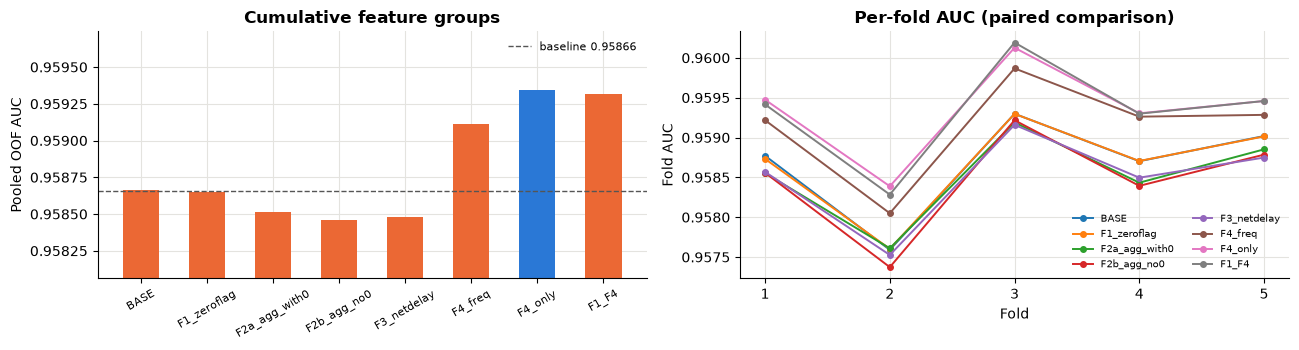

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))

names = [r["name"] for r in results]
pooled = [r["pooled"] for r in results]
colors = [COLOR_MAIN if p >= max(pooled) else COLOR_ALT for p in pooled]
axes[0].bar(names, pooled, color=colors, width=0.55)
axes[0].axhline(0.95866, color="#555", linestyle="--", linewidth=1, label="baseline 0.95866")
axes[0].set_ylim(min(pooled) - 0.0004, max(pooled) + 0.0004)
axes[0].set_ylabel("Pooled OOF AUC")
axes[0].set_title("Cumulative feature groups")
axes[0].tick_params(axis="x", rotation=30, labelsize=8)
axes[0].legend(frameon=False, fontsize=8)

for r in results:
    axes[1].plot(range(1, 6), r["folds"], marker="o", markersize=4, linewidth=1.4, label=r["name"])
axes[1].set_xticks(range(1, 6))
axes[1].set_xlabel("Fold")
axes[1].set_ylabel("Fold AUC")
axes[1].set_title("Per-fold AUC (paired comparison)")
axes[1].legend(frameon=False, fontsize=7, ncol=2)
plt.tight_layout()
plt.show()

## 6. 최종 구성 저장 및 중요도 (Final Artifact & Importance)

채택된 구성으로 예측을 `oof_lgbm_fe.csv` / `test_lgbm_fe.csv` 에 저장한다 (§3-2 산출물 계약).
기준선을 넘지 못했다면 저장하지 않고 **기준선 구성을 유지**한다.

lgbm_fe          n_feat= 23  OOF=0.95934  folds=[0.95947, 0.95839, 0.96013, 0.9593, 0.95946]  trees=[653, 635, 623, 501, 394]  60s

저장 완료: oof_lgbm_fe.csv / test_lgbm_fe.csv  (OOF 0.95934)


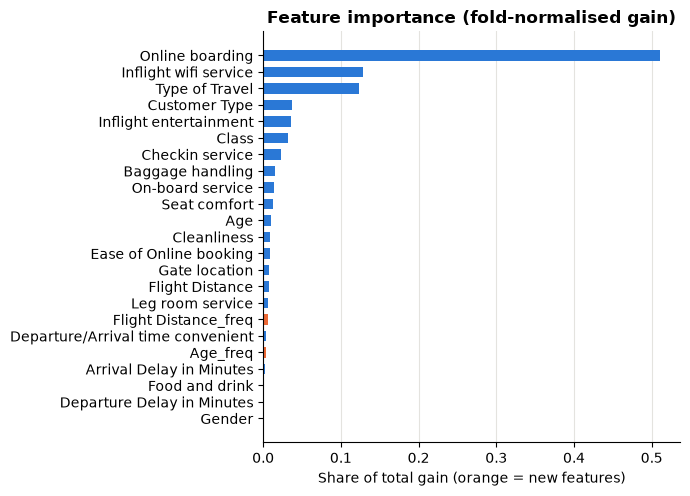


신규 피처 중요도 합계: 0.99%

전체 실행 시간: 468초


In [11]:
BASELINE_AUC = 0.95866

if kept["pooled"] > BASELINE_AUC:
    cfg = {"BASE": (X, X_test, False), "F1_zeroflag": (X1, X1t, False),
           "F2a_agg_with0": (X2a, X2at, False), "F2b_agg_no0": (X2b, X2bt, False),
           "F3_netdelay": (X3, X3t, False), "F4_freq": (X3, X3t, True),
           "F4_only": (X, X_test, True), "F1_F4": (X1, X1t, True)}[kept["name"]]
    final = evaluate(cfg[0], cfg[1], "lgbm_fe", use_freq=cfg[2], save=True)
    print(f"\n저장 완료: oof_lgbm_fe.csv / test_lgbm_fe.csv  (OOF {final['pooled']:.5f})")

    imp = pd.Series(0.0, index=None, dtype=float)
    gains = []
    for tr_idx, va_idx in FOLDS:
        X_tr, X_va, X_te = cfg[0].iloc[tr_idx], cfg[0].iloc[va_idx], cfg[1]
        if cfg[2]:
            X_tr, X_va, X_te = add_freq_features(X_tr, X_va, X_te)
        dtrain = lgb.Dataset(X_tr, label=y.iloc[tr_idx])
        dvalid = lgb.Dataset(X_va, label=y.iloc[va_idx], reference=dtrain)
        m = lgb.train(LGB_PARAMS, dtrain, num_boost_round=5000, valid_sets=[dvalid],
                      callbacks=[lgb.early_stopping(100, verbose=False)])
        g = pd.Series(m.feature_importance("gain"), index=X_tr.columns)
        gains.append(g / g.sum())           # fold별 정규화 후 평균 (§1-5 서술 결함 수정)
    imp = pd.concat(gains, axis=1).mean(axis=1).sort_values()

    fig, ax = plt.subplots(figsize=(7, max(5, len(imp) * 0.22)))
    new_feats = set(imp.index) - set(X.columns)
    ax.barh(imp.index, imp.values, height=0.65,
            color=[COLOR_ALT if f in new_feats else COLOR_MAIN for f in imp.index])
    ax.set_xlabel("Share of total gain (orange = new features)")
    ax.set_title("Feature importance (fold-normalised gain)")
    ax.grid(axis="y", visible=False)
    plt.tight_layout()
    plt.show()
    print("\n신규 피처 중요도 합계: {:.2%}".format(imp[list(new_feats)].sum()))
else:
    print(f"기준선 미달 ({kept['pooled']:.5f} <= {BASELINE_AUC}) — 저장하지 않고 기준선 구성 유지")

summary.to_csv(REPORT_DIR / "step1_summary.csv", index=False)
print(f"\n전체 실행 시간: {time.time() - START_TIME:.0f}초")